In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

folder = Path(r"C:\Users\ADMIN\ADAS_Program9")
folder.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(42)
rows = []

# Generate smooth road readings
for i in range(60):
    speed = rng.uniform(20, 90)
    accel = rng.uniform(0.05, 0.30)
    vibration = rng.uniform(0.05, 0.30)
    roughness = rng.uniform(0.5, 2.5)

    rows.append([speed, accel, vibration, roughness, "Smooth"])

# Generate rough road readings
for i in range(60):
    speed = rng.uniform(20, 90)
    accel = rng.uniform(0.40, 1.20)
    vibration = rng.uniform(0.40, 1.50)
    roughness = rng.uniform(3.0, 8.0)

    rows.append([speed, accel, vibration, roughness, "Rough"])

data = pd.DataFrame(rows, columns=[
    "speed",
    "accel_rms",
    "vibration_rms",
    "roughness_index",
    "surface"
])

data.to_csv(folder / "road_sensor.csv", index=False)

print("Dataset created successfully!")
print("Total records:", len(data))
print(data.head())

Dataset created successfully!
Total records: 120
       speed  accel_rms  vibration_rms  roughness_index surface
0  74.176923   0.159720       0.264649         1.894736  Smooth
1  26.592414   0.293906       0.240285         2.072129  Smooth
2  28.967954   0.162596       0.142700         2.353530  Smooth
3  65.070558   0.255690       0.160854         0.954477  Smooth
4  58.820935   0.065954       0.256908         1.763329  Smooth


Accuracy: 0.9666666666666667
Confusion Matrix:
[[14  1]
 [ 0 15]]
Predicted road surface: Rough


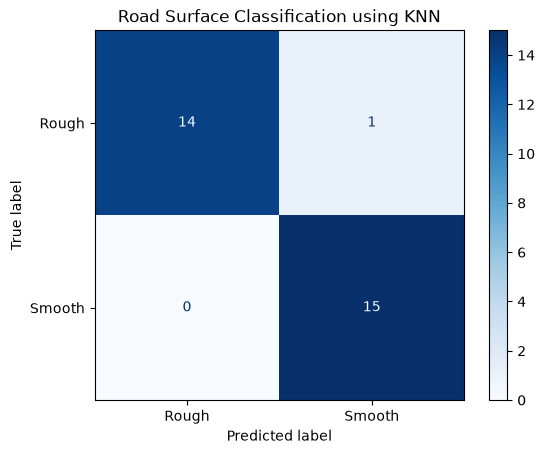

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Load dataset
data = pd.read_csv(
    r"C:\Users\ADMIN\ADAS_Program9\road_sensor.csv"
)

# Input features
features = [
    "speed",
    "accel_rms",
    "vibration_rms",
    "roughness_index"
]

X = data[features]
y = data["surface"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Create KNN model
model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(
        n_neighbors=5,
        weights="distance"
    ))
])

# Train model
model.fit(X_train, y_train)

# Predict test data
pred = model.predict(X_test)

# Display accuracy
print("Accuracy:", accuracy_score(y_test, pred))

# Display confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, pred))

# Test new road reading
new_reading = pd.DataFrame(
    [[60, 0.35, 0.42, 3.1]],
    columns=features
)

print("Predicted road surface:", model.predict(new_reading)[0])

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, pred,
    cmap="Blues"
)

plt.title("Road Surface Classification using KNN")
plt.show()